## Step 1: Load the DataSet

In [29]:
import pandas as pd
import numpy as np

In [30]:
# Load the dataset

data = pd.read_csv("../data/sampledata.csv")
data

,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,1/15/2023,HR
1,Jane,NaN,65000.0,8/1/2022,Finance
2,Alice,22.0,71350.0,5/20/2021,HR
3,Bob,22.0,NaN,1/15/2023,IT
4,Pam,25.0,71250.0,1/15/2023,HR
5,Jade,40.0,NaN,1/15/2023,Finance
6,Joanne,25.0,120000.0,1/16/2023,IT
7,Kim,33.0,71568.0,8/30/2021,HR
8,Sam,40.0,NaN,9/5/2022,IT
9,Eli,NaN,80100.0,3/4/2022,HR


## Step: 2 Identify Missing Values

In [31]:
print("\nMissing Values Count:")
print(data.isnull().sum())


Missing Values Count:
Name          0
Age           4
Salary        7
Join_Date     0
Department    0
dtype: int64


## Step:3 Handling Missing Values

## Step:4 Check and remove duplicate rows

In [32]:
data = data.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

In [33]:
data = data.apply(lambda x: x.str.lower() if x.dtype == "object" else x)
data

,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,1/15/2023,HR
1,Jane,NaN,65000.0,8/1/2022,Finance
2,Alice,22.0,71350.0,5/20/2021,HR
3,Bob,22.0,NaN,1/15/2023,IT
4,Pam,25.0,71250.0,1/15/2023,HR
5,Jade,40.0,NaN,1/15/2023,Finance
6,Joanne,25.0,120000.0,1/16/2023,IT
7,Kim,33.0,71568.0,8/30/2021,HR
8,Sam,40.0,NaN,9/5/2022,IT
9,Eli,NaN,80100.0,3/4/2022,HR


In [34]:
data = data.drop_duplicates(subset=["Name","Age"])
data

,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,1/15/2023,HR
1,Jane,NaN,65000.0,8/1/2022,Finance
2,Alice,22.0,71350.0,5/20/2021,HR
3,Bob,22.0,NaN,1/15/2023,IT
5,Jade,40.0,NaN,1/15/2023,Finance
6,Joanne,25.0,120000.0,1/16/2023,IT
7,Kim,33.0,71568.0,8/30/2021,HR
8,Sam,40.0,NaN,9/5/2022,IT
9,Eli,NaN,80100.0,3/4/2022,HR
10,Joe,22.0,62000.0,10/9/2022,Finance


In [35]:
print(data.duplicated().sum())

0


## Step:5 Handle Outliers

In [36]:
# Calculate population quartiles
Q1 = data['Salary'].quantile(0.25)
Q3 = data['Salary'].quantile(0.75)

IQR = Q3 - Q1

data = data[(data['Salary']>= Q1 - 1.5 * IQR) & (data['Salary']<= Q3 + 1.5 * IQR)]
data

,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,1/15/2023,HR
1,Jane,NaN,65000.0,8/1/2022,Finance
2,Alice,22.0,71350.0,5/20/2021,HR
7,Kim,33.0,71568.0,8/30/2021,HR
9,Eli,NaN,80100.0,3/4/2022,HR
10,Joe,22.0,62000.0,10/9/2022,Finance
11,Anna,36.0,72456.0,4/6/2022,HR
13,Susan,46.0,66000.0,5/3/2022,Finance
14,Pamela,NaN,77421.0,4/2/2023,HR
16,Ruth,30.0,72114.0,9/5/2022,HR


## Step:6 Convert DataTypes

In [37]:
data['Join_Date'] = pd.to_datetime(data['Join_Date'])
data

,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,2023-01-15,HR
1,Jane,NaN,65000.0,2022-08-01,Finance
2,Alice,22.0,71350.0,2021-05-20,HR
7,Kim,33.0,71568.0,2021-08-30,HR
9,Eli,NaN,80100.0,2022-03-04,HR
10,Joe,22.0,62000.0,2022-10-09,Finance
11,Anna,36.0,72456.0,2022-04-06,HR
13,Susan,46.0,66000.0,2022-05-03,Finance
14,Pamela,NaN,77421.0,2023-04-02,HR
16,Ruth,30.0,72114.0,2022-09-05,HR


## Step:7 Encode Categorical Values

In [38]:
#one-hit encode the Department column
data = pd.get_dummies(data, columns=['Department'],drop_first=True)

#Convert only the one-hot encoded columns to integers
binary_columns = [col for col in data.columns if col.startswith("Department_")]
data[binary_columns] = data[binary_columns].astype(int)

print(data)


        Name   Age   Salary  Join_Date  Department_HR  Department_IT
0        Pam  25.0  70200.0 2023-01-15              1              0
1       Jane   NaN  65000.0 2022-08-01              0              0
2      Alice  22.0  71350.0 2021-05-20              1              0
7        Kim  33.0  71568.0 2021-08-30              1              0
9        Eli   NaN  80100.0 2022-03-04              1              0
10       Joe  22.0  62000.0 2022-10-09              0              0
11      Anna  36.0  72456.0 2022-04-06              1              0
13     Susan  46.0  66000.0 2022-05-03              0              0
14    Pamela   NaN  77421.0 2023-04-02              1              0
16      Ruth  30.0  72114.0 2022-09-05              1              0
19     Clark  44.0  76982.0 2023-01-28              1              0
20    Alissa  36.0  77421.0 2022-10-05              1              0
22   Anthony  30.0  61000.0 2021-08-06              0              0
23       Eli  21.0  77421.0 2022-0

## Step:9 Save the dataset 

In [39]:
data.to_csv("Cleaned_new_dataset.csv",index=False)


## Visualization 

In [40]:
import matplotlib.pyplot as plt

#Load the dataset
data = pd.read_csv("../data/Cleaned_new_dataset.csv")

#Display the first few rows of the datasets
print(data.head())

    Name   Age   Salary   Join_Date  Department_HR  Department_IT
0    Pam  25.0  70200.0  2023-01-15              1              0
1   Jane   NaN  65000.0  2022-08-01              0              0
2  Alice  22.0  71350.0  2021-05-20              1              0
3    Kim  33.0  71568.0  2021-08-30              1              0
4    Eli   NaN  80100.0  2022-03-04              1              0


## Bar Chart for Department 

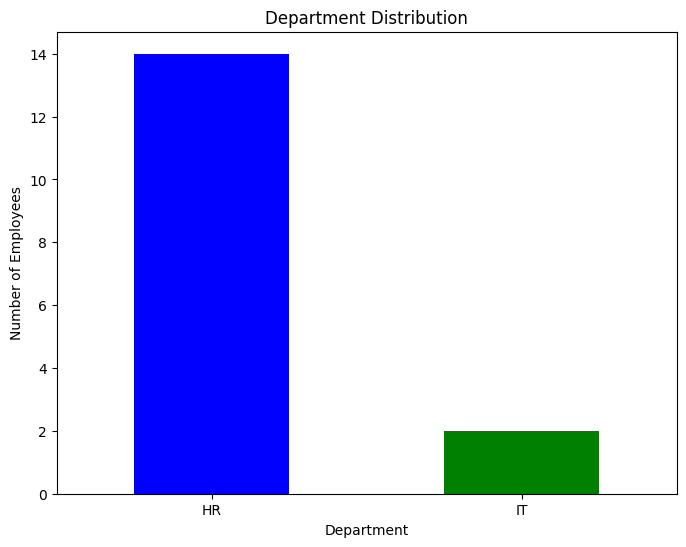

In [41]:
dept = data[['Department_HR','Department_IT']].sum()

#Plotting department distribution
dept.plot(kind='bar', color=['blue','green'],figsize=(8,6))
plt.title("Department Distribution")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(ticks=[0,1], labels=['HR','IT'], rotation=0)
plt.show()


## Histogram for Salaries

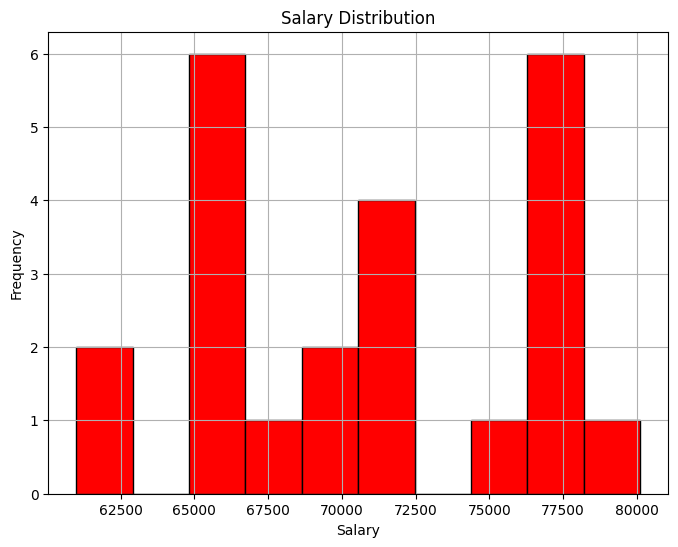

In [42]:
plt.figure(figsize=(8,6))
plt.hist(data['Salary'], bins=10, color='red', edgecolor='black')
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()


## Line Plot for Age and Salary

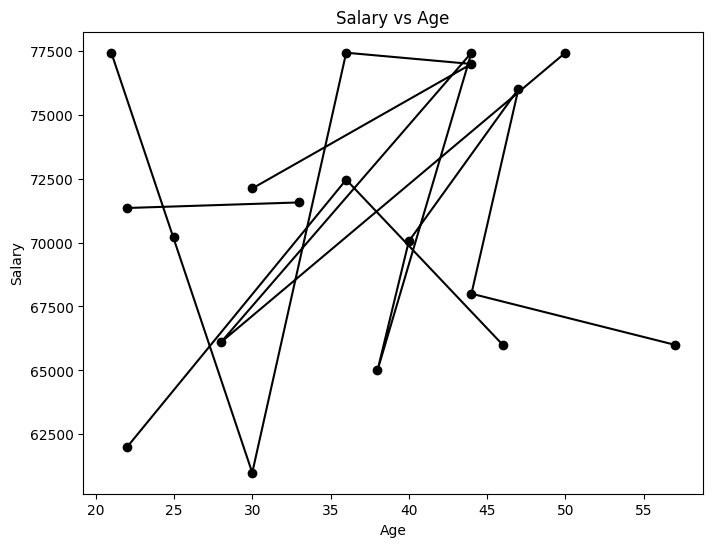

In [43]:
plt.figure(figsize=(8,6))
plt.plot(data['Age'], data['Salary'],marker='o', linestyle='-',color='black')
plt.title("Salary vs Age")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.grid(False)
plt.show()

## Scatter plot for Salary and Department

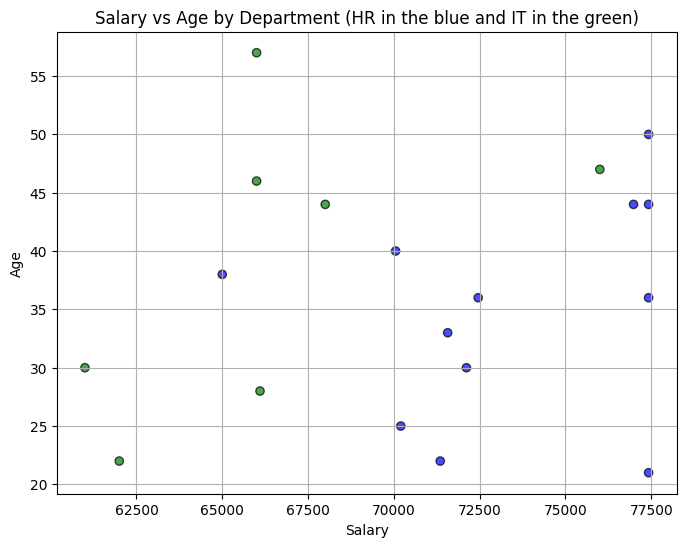

In [44]:
plt.figure(figsize=(8,6))
colors = ['blue' if dept == 1 else 'green' for dept in data['Department_HR']]
plt.scatter(data['Salary'], data['Age'], c=colors, alpha=0.7, edgecolor='black')
plt.title("Salary vs Age by Department (HR in the blue and IT in the green)")
plt.xlabel("Salary")
plt.ylabel("Age")
plt.grid(True)
plt.show()
